In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.12.2 (tags/v3.12.2:6abddd9, Feb  6 2024, 21:26:36) [MSC v.1937 64 bit (AMD64)]
Python executable: c:\forecasting_challenge\forecasting-challenge\.venv\Scripts\python.exe


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
NumPy version: 2.5.4


In [4]:
from pathlib import Path

DATA_DIR = Path("../challenge_data")

print("Data directory:", DATA_DIR.resolve())
print("\nFiles found:")

for file in DATA_DIR.iterdir():
    print("-", file.name)

Data directory: C:\forecasting_challenge\forecasting-challenge\challenge_data

Files found:
- DATA_CARD.md
- README.md
- SHA256SUMS
- vm_cpu_readings.csv.gz
- vm_metadata.csv.gz


In [5]:
metadata_path = DATA_DIR / "vm_metadata.csv.gz"

metadata = pd.read_csv(metadata_path)

print("Shape:", metadata.shape)
print("\nColumns:")
print(metadata.columns.tolist())

print("\nFirst 5 rows:")
display(metadata.head())

Shape: (10000, 11)

Columns:
['vm_id', 'subscription_id', 'deployment_id', 'timestamp_vm_created', 'timestamp_vm_deleted', 'max_cpu', 'avg_cpu', 'p95_max_cpu', 'vm_category', 'virtual_core_bucket', 'memory_gb_bucket']

First 5 rows:


,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


In [6]:
metadata.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   vm_id                 10000 non-null  str    
 1   subscription_id       10000 non-null  str    
 2   deployment_id         10000 non-null  str    
 3   timestamp_vm_created  10000 non-null  int64  
 4   timestamp_vm_deleted  10000 non-null  int64  
 5   max_cpu               10000 non-null  float64
 6   avg_cpu               10000 non-null  float64
 7   p95_max_cpu           10000 non-null  float64
 8   vm_category           10000 non-null  str    
 9   virtual_core_bucket   10000 non-null  str    
 10  memory_gb_bucket      10000 non-null  str    
dtypes: float64(3), int64(2), str(6)
memory usage: 859.5 KB


In [7]:
print("Missing values:")
display(metadata.isna().sum())

print("\nDuplicate rows:", metadata.duplicated().sum())

print("Duplicate VM IDs:", metadata["vm_id"].duplicated().sum())

Missing values:


vm_id                   0
subscription_id         0
deployment_id           0
timestamp_vm_created    0
timestamp_vm_deleted    0
max_cpu                 0
avg_cpu                 0
p95_max_cpu             0
vm_category             0
virtual_core_bucket     0
memory_gb_bucket        0
dtype: int64


Duplicate rows: 0
Duplicate VM IDs: 0


In [8]:
print("VM creation timestamps:")
print(metadata["timestamp_vm_created"].describe())

print("\nVM deletion timestamps:")
print(metadata["timestamp_vm_deleted"].describe())

VM creation timestamps:
count    10000.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: timestamp_vm_created, dtype: float64

VM deletion timestamps:
count    1.000000e+04
mean     2.289626e+06
std      7.081008e+05
min      4.050000e+04
25%      2.591400e+06
50%      2.591400e+06
75%      2.591400e+06
max      2.591400e+06
Name: timestamp_vm_deleted, dtype: float64


In [9]:
cpu_path = DATA_DIR / "vm_cpu_readings.csv.gz"

cpu_sample = pd.read_csv(cpu_path, nrows=10)

print("Columns:")
print(cpu_sample.columns.tolist())

print("\nShape of sample:")
print(cpu_sample.shape)

print("\nFirst 10 rows:")
display(cpu_sample)

Columns:
['timestamp', 'vm_id', 'min_cpu', 'max_cpu', 'avg_cpu']

Shape of sample:
(10, 5)

First 10 rows:


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535
5,0,fLgT0pGZYryGeTyfSQtTdcTiDFnNmMk4CLNFaMUWayF6LF...,17.942749,73.475383,47.959679
6,0,5vZplAoVcVDjtEqFnwiwWwClARKx0Q5zAe7aL/eRPyyN7P...,6.196960,10.492448,8.279646
7,0,axlgaRUC/rriBDz72FFJeXhrXv/Yg30JJpDPZh3VPMRLSD...,0.436415,0.680972,0.511560
8,0,M5pEZDXtBcVLbecnopAS90We2GGza3rC3a9W5t+WdjdTzG...,1.952879,3.538291,2.288922
9,0,Uy52PQmE533hPkLvud8MVAhhHEtKaWrlTBfaC5tASVF3ED...,4.734145,11.387052,5.719706


In [10]:
timestamp_sample = pd.read_csv(
    cpu_path,
    usecols=["timestamp"]
)

print("Number of CPU observations:", len(timestamp_sample))
print("Number of unique timestamps:", timestamp_sample["timestamp"].nunique())

print("\nFirst timestamps:")
print(timestamp_sample["timestamp"].drop_duplicates().head(10).to_list())

print("\nLast timestamps:")
print(timestamp_sample["timestamp"].drop_duplicates().tail(10).to_list())

Number of CPU observations: 1340000
Number of unique timestamps: 134

First timestamps:
[0, 300, 600, 900, 1200, 1500, 1800, 2100, 2400, 2700]

Last timestamps:
[37200, 37500, 37800, 38100, 38400, 38700, 39000, 39300, 39600, 39900]


In [12]:
# Check timestamp intervals
unique_timestamps = timestamp_sample["timestamp"].drop_duplicates()
timestamp_diffs = unique_timestamps.diff().dropna()

print(timestamp_diffs.value_counts())
print("All intervals are 5 minutes:", (timestamp_diffs == 300).all())

timestamp
300.0    133
Name: count, dtype: int64
All intervals are 5 minutes: True


In [13]:
# Load the full CPU dataset
cpu = pd.read_csv(cpu_path)

print("Shape:", cpu.shape)
display(cpu.head())


Shape: (1340000, 5)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [14]:
cpu = pd.read_csv(cpu_path)

print("Shape:", cpu.shape)
display(cpu.head())


Shape: (1340000, 5)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [15]:
print("Missing values:")
print(cpu.isna().sum())

print("\nDuplicate rows:", cpu.duplicated().sum())
print("Duplicate VM-timestamp pairs:", cpu.duplicated(["timestamp", "vm_id"]).sum())

Missing values:
timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64

Duplicate rows: 0
Duplicate VM-timestamp pairs: 0


In [16]:
print(cpu[["min_cpu", "max_cpu", "avg_cpu"]].describe())


            min_cpu       max_cpu       avg_cpu
count  1.340000e+06  1.340000e+06  1.340000e+06
mean   6.156478e+00  1.834830e+01  9.388101e+00
std    1.175525e+01  2.161651e+01  1.426601e+01
min    0.000000e+00  1.810795e-02  7.158922e-03
25%    1.487979e+00  4.417642e+00  2.477060e+00
50%    3.227996e+00  9.124204e+00  5.105133e+00
75%    5.331087e+00  2.362418e+01  9.616715e+00
max    9.928158e+01  9.970286e+01  9.948803e+01


In [17]:
targets = (
    cpu.groupby("timestamp")
       .agg(
           active_vm_count=("vm_id", "nunique"),
           aggregate_cpu_utilization=("avg_cpu", "mean")
       )
       .reset_index()
)

display(targets.head())
print("Shape:", targets.shape)

,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383
3,900,10000,9.224419
4,1200,10000,9.143503


Shape: (134, 3)


In [18]:
print(targets.tail())

print("\nActive VM count:")
print(targets["active_vm_count"].value_counts().sort_index())

print("\nMissing values:")
print(targets.isna().sum())

     timestamp  active_vm_count  aggregate_cpu_utilization
129      38700            10000                   9.430236
130      39000            10000                   9.307138
131      39300            10000                   9.499973
132      39600            10000                   9.423042
133      39900            10000                   9.428117

Active VM count:
active_vm_count
10000    134
Name: count, dtype: int64

Missing values:
timestamp                    0
active_vm_count              0
aggregate_cpu_utilization    0
dtype: int64


In [19]:
train = targets.iloc[:110].copy()
holdout = targets.iloc[110:].copy()

print("Training timestamps:", len(train))
print("Holdout timestamps:", len(holdout))

print("\nTraining range:")
print(train["timestamp"].iloc[0], "to", train["timestamp"].iloc[-1])

print("\nHoldout range:")
print(holdout["timestamp"].iloc[0], "to", holdout["timestamp"].iloc[-1])

Training timestamps: 110
Holdout timestamps: 24

Training range:
0 to 32700

Holdout range:
33000 to 39900


In [20]:
print(train[["active_vm_count", "aggregate_cpu_utilization"]].describe())

print("\nLast 5 training values:")
display(train.tail())


       active_vm_count  aggregate_cpu_utilization
count            110.0                 110.000000
mean           10000.0                   9.414089
std                0.0                   0.193568
min            10000.0                   9.111634
25%            10000.0                   9.288952
50%            10000.0                   9.378121
75%            10000.0                   9.507673
max            10000.0                   9.912175

Last 5 training values:


,timestamp,active_vm_count,aggregate_cpu_utilization
105,31500,10000,9.280858
106,31800,10000,9.119565
107,32100,10000,9.218538
108,32400,10000,9.111634
109,32700,10000,9.164556


In [21]:
train_model = train.iloc[:-24].copy()
validation = train.iloc[-24:].copy()

print("Modeling data:", len(train_model))
print("Validation data:", len(validation))

print("\nValidation range:")
print(validation["timestamp"].iloc[0], "to", validation["timestamp"].iloc[-1])

Modeling data: 86
Validation data: 24

Validation range:
25800 to 32700


In [22]:
last_cpu = train_model["aggregate_cpu_utilization"].iloc[-1]
last_vm_count = train_model["active_vm_count"].iloc[-1]

naive_cpu = np.repeat(last_cpu, len(validation))
naive_vm_count = np.repeat(last_vm_count, len(validation))

print("Last observed CPU:", last_cpu)
print("Last observed VM count:", last_vm_count)

Last observed CPU: 9.366770780677678
Last observed VM count: 10000


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

cpu_mae = mean_absolute_error(
    validation["aggregate_cpu_utilization"],
    naive_cpu
)

cpu_rmse = np.sqrt(
    mean_squared_error(
        validation["aggregate_cpu_utilization"],
        naive_cpu
    )
)

vm_mae = mean_absolute_error(
    validation["active_vm_count"],
    naive_vm_count
)

print("Naive CPU MAE:", cpu_mae)
print("Naive CPU RMSE:", cpu_rmse)
print("Naive VM count MAE:", vm_mae)

Naive CPU MAE: 0.13242942454439147
Naive CPU RMSE: 0.15422831245835641
Naive VM count MAE: 0.0


In [25]:
for lag in [1, 2, 3, 6, 12, 24]:
    print(
        f"Lag {lag}:",
        train_model["aggregate_cpu_utilization"].autocorr(lag=lag)
    )

Lag 1: 0.6334491949052832
Lag 2: 0.5696601043312848
Lag 3: 0.6174545494913888
Lag 6: 0.37743736614119544
Lag 12: 0.18467557910294863
Lag 24: -0.04415399301218585


In [26]:
history = train_model["aggregate_cpu_utilization"].tolist()
rolling_predictions = []

for _ in range(len(validation)):
    prediction = np.mean(history[-3:])
    rolling_predictions.append(prediction)
    history.append(prediction)

rolling_mae = mean_absolute_error(
    validation["aggregate_cpu_utilization"],
    rolling_predictions
)

rolling_rmse = np.sqrt(
    mean_squared_error(
        validation["aggregate_cpu_utilization"],
        rolling_predictions
    )
)

print("Rolling mean CPU MAE:", rolling_mae)
print("Rolling mean CPU RMSE:", rolling_rmse)


Rolling mean CPU MAE: 0.12622972515015443
Rolling mean CPU RMSE: 0.14736422047976194


In [27]:
windows = [3, 6, 12, 24]
results = []

for window in windows:
    history = train_model["aggregate_cpu_utilization"].tolist()
    predictions = []

    for _ in range(len(validation)):
        prediction = np.mean(history[-window:])
        predictions.append(prediction)
        history.append(prediction)

    mae = mean_absolute_error(
        validation["aggregate_cpu_utilization"],
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation["aggregate_cpu_utilization"],
            predictions
        )
    )

    results.append({
        "window_minutes": window * 5,
        "mae": mae,
        "rmse": rmse
    })

rolling_results = pd.DataFrame(results)
display(rolling_results)

,window_minutes,mae,rmse
0,15,0.126230,0.147364
1,30,0.132409,0.153684
2,60,0.124644,0.147283
3,120,0.186218,0.210712


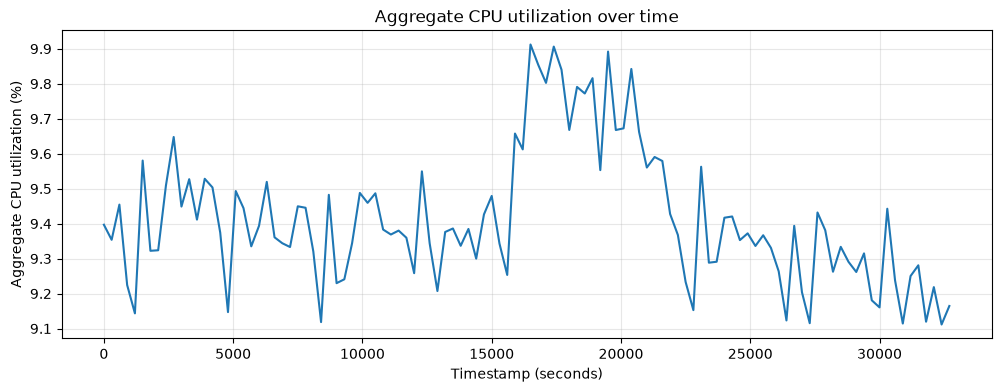

In [28]:
plt.figure(figsize=(12, 4))

plt.plot(
    train["timestamp"],
    train["aggregate_cpu_utilization"]
)

plt.xlabel("Timestamp (seconds)")
plt.ylabel("Aggregate CPU utilization (%)")
plt.title("Aggregate CPU utilization over time")
plt.grid(alpha=0.3)

plt.show()

In [29]:
from sklearn.linear_model import LinearRegression

lags = [1, 2, 3, 6, 12]

model_data = train_model[["aggregate_cpu_utilization"]].copy()

for lag in lags:
    model_data[f"lag_{lag}"] = model_data["aggregate_cpu_utilization"].shift(lag)

model_data = model_data.dropna()

X = model_data[[f"lag_{lag}" for lag in lags]]
y = model_data["aggregate_cpu_utilization"]

ar_model = LinearRegression()
ar_model.fit(X, y)

print("Training rows:", len(model_data))
print("R²:", ar_model.score(X, y))

Training rows: 74
R²: 0.5625072331337306


In [30]:
history = train_model["aggregate_cpu_utilization"].tolist()
ar_predictions = []

for _ in range(len(validation)):
    features = [
        history[-1],
        history[-2],
        history[-3],
        history[-6],
        history[-12]
    ]

    prediction = ar_model.predict([features])[0]
    ar_predictions.append(prediction)
    history.append(prediction)

ar_mae = mean_absolute_error(
    validation["aggregate_cpu_utilization"],
    ar_predictions
)

ar_rmse = np.sqrt(
    mean_squared_error(
        validation["aggregate_cpu_utilization"],
        ar_predictions
    )
)

print("AR CPU MAE:", ar_mae)
print("AR CPU RMSE:", ar_rmse)

AR CPU MAE: 0.1277856289700486
AR CPU RMSE: 0.14913722354028794


c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: Use

In [31]:
comparison = pd.DataFrame({
    "model": [
        "Naive",
        "Rolling mean (15 min)",
        "Rolling mean (60 min)",
        "AR"
    ],
    "mae": [
        cpu_mae if False else 0.13242942454439147,
        0.12622972515015443,
        0.124644,
        ar_mae
    ],
    "rmse": [
        0.15422831245835641,
        0.14736422047976194,
        0.147283,
        ar_rmse
    ]
})

display(comparison.sort_values("mae"))

,model,mae,rmse
2,Rolling mean (60 min),0.124644,0.147283
1,Rolling mean (15 min),0.126230,0.147364
3,AR,0.127786,0.149137
0,Naive,0.132429,0.154228


In [32]:
origins = [62, 70, 78, 86]

print("Forecast origins:", origins)

for origin in origins:
    print(
        f"Origin {origin}: "
        f"train={origin} points, "
        f"forecast={len(train) - origin} points available"
    )

Forecast origins: [62, 70, 78, 86]
Origin 62: train=62 points, forecast=48 points available
Origin 70: train=70 points, forecast=40 points available
Origin 78: train=78 points, forecast=32 points available
Origin 86: train=86 points, forecast=24 points available


In [33]:
cv_results = []

for origin in origins:
    history = train["aggregate_cpu_utilization"].iloc[:origin].tolist()
    actual = train["aggregate_cpu_utilization"].iloc[origin:origin + 24]

    predictions = []

    for _ in range(24):
        prediction = np.mean(history[-12:])
        predictions.append(prediction)
        history.append(prediction)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    cv_results.append({
        "origin": origin,
        "mae": mae,
        "rmse": rmse
    })

cv_results = pd.DataFrame(cv_results)

display(cv_results)

print("\nAverage MAE:", cv_results["mae"].mean())
print("Average RMSE:", cv_results["rmse"].mean())


,origin,mae,rmse
0,62,0.276895,0.317251
1,70,0.381089,0.402413
2,78,0.151391,0.178432
3,86,0.124644,0.147283



Average MAE: 0.23350500470839208
Average RMSE: 0.26134474751954617


In [34]:
train_with_step = train.copy()
train_with_step["step"] = np.arange(len(train_with_step))

print(
    train_with_step[["step", "aggregate_cpu_utilization"]]
    .corr()
)

                               step  aggregate_cpu_utilization
step                       1.000000                  -0.174278
aggregate_cpu_utilization -0.174278                   1.000000


In [35]:
model_data = train_model[["aggregate_cpu_utilization"]].copy()

model_data["lag_1"] = model_data["aggregate_cpu_utilization"].shift(1)
model_data["rolling_12"] = (
    model_data["aggregate_cpu_utilization"]
    .shift(1)
    .rolling(12)
    .mean()
)

model_data = model_data.dropna()

X = model_data[["lag_1", "rolling_12"]]
y = model_data["aggregate_cpu_utilization"]

trend_model = LinearRegression()
trend_model.fit(X, y)

print("Training rows:", len(model_data))
print("Coefficients:", trend_model.coef_)

Training rows: 74
Coefficients: [0.57708254 0.23149662]


In [36]:
history = train_model["aggregate_cpu_utilization"].tolist()
trend_predictions = []

for _ in range(len(validation)):
    lag_1 = history[-1]
    rolling_12 = np.mean(history[-12:])

    prediction = trend_model.predict(
        [[lag_1, rolling_12]]
    )[0]

    trend_predictions.append(prediction)
    history.append(prediction)

trend_mae = mean_absolute_error(
    validation["aggregate_cpu_utilization"],
    trend_predictions
)

trend_rmse = np.sqrt(
    mean_squared_error(
        validation["aggregate_cpu_utilization"],
        trend_predictions
    )
)

print("Lag + rolling mean MAE:", trend_mae)
print("Lag + rolling mean RMSE:", trend_rmse)

Lag + rolling mean MAE: 0.1718241217680283
Lag + rolling mean RMSE: 0.19937101796174253


c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: Use

In [37]:
model_data = train_model[["aggregate_cpu_utilization"]].copy()

for lag in [1, 2, 3, 6, 12]:
    model_data[f"lag_{lag}"] = (
        model_data["aggregate_cpu_utilization"].shift(lag)
    )

model_data["rolling_12"] = (
    model_data["aggregate_cpu_utilization"]
    .shift(1)
    .rolling(12)
    .mean()
)

model_data = model_data.dropna()

X = model_data.drop(columns="aggregate_cpu_utilization")
y = model_data["aggregate_cpu_utilization"]

print("Training rows:", len(model_data))
print("Features:", X.columns.tolist())

Training rows: 74
Features: ['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'rolling_12']


In [38]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

rf_model.fit(X, y)

print("Random Forest trained.")


Random Forest trained.


In [39]:
history = train_model["aggregate_cpu_utilization"].tolist()
rf_predictions = []

for _ in range(len(validation)):
    features = [
        history[-1],
        history[-2],
        history[-3],
        history[-6],
        history[-12],
        np.mean(history[-12:])
    ]

    prediction = rf_model.predict([features])[0]
    rf_predictions.append(prediction)
    history.append(prediction)

rf_mae = mean_absolute_error(
    validation["aggregate_cpu_utilization"],
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        validation["aggregate_cpu_utilization"],
        rf_predictions
    )
)

print("Random Forest CPU MAE:", rf_mae)
print("Random Forest CPU RMSE:", rf_rmse)


c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\val

Random Forest CPU MAE: 0.12660213243935278
Random Forest CPU RMSE: 0.14567881471899605


In [40]:
rf_cv_results = []

for origin in origins:
    history = train["aggregate_cpu_utilization"].iloc[:origin].tolist()
    actual = train["aggregate_cpu_utilization"].iloc[origin:origin + 24]

    predictions = []

    for _ in range(24):
        features = [
            history[-1],
            history[-2],
            history[-3],
            history[-6],
            history[-12],
            np.mean(history[-12:])
        ]

        prediction = rf_model.predict([features])[0]
        predictions.append(prediction)
        history.append(prediction)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    rf_cv_results.append({
        "origin": origin,
        "mae": mae,
        "rmse": rmse
    })

rf_cv_results = pd.DataFrame(rf_cv_results)

display(rf_cv_results)

print("\nAverage MAE:", rf_cv_results["mae"].mean())
print("Average RMSE:", rf_cv_results["rmse"].mean())

c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\val

,origin,mae,rmse
0,62,0.237081,0.292446
1,70,0.357092,0.387022
2,78,0.078274,0.097338
3,86,0.126602,0.145679



Average MAE: 0.19976226992055676
Average RMSE: 0.2306213263006391


In [41]:
rf_cv_results = []

for origin in origins:
    history = train["aggregate_cpu_utilization"].iloc[:origin].tolist()

    model_data = pd.DataFrame({
        "y": history
    })

    for lag in [1, 2, 3, 6, 12]:
        model_data[f"lag_{lag}"] = model_data["y"].shift(lag)

    model_data["rolling_12"] = (
        model_data["y"]
        .shift(1)
        .rolling(12)
        .mean()
    )

    model_data = model_data.dropna()

    X_cv = model_data.drop(columns="y")
    y_cv = model_data["y"]

    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        random_state=42
    )

    model.fit(X_cv, y_cv)

    actual = train["aggregate_cpu_utilization"].iloc[
        origin:origin + 24
    ]

    predictions = []

    for _ in range(24):
        features = [[
            history[-1],
            history[-2],
            history[-3],
            history[-6],
            history[-12],
            np.mean(history[-12:])
        ]]

        prediction = model.predict(features)[0]
        predictions.append(prediction)
        history.append(prediction)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    rf_cv_results.append({
        "origin": origin,
        "mae": mae,
        "rmse": rmse
    })

rf_cv_results = pd.DataFrame(rf_cv_results)

display(rf_cv_results)

print("\nAverage MAE:", rf_cv_results["mae"].mean())
print("Average RMSE:", rf_cv_results["rmse"].mean())


c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\forecasting_challenge\forecasting-challenge\.venv\Lib\site-packages\sklearn\utils\val

,origin,mae,rmse
0,62,0.288534,0.336416
1,70,0.407493,0.429090
2,78,0.091596,0.116775
3,86,0.126602,0.145679



Average MAE: 0.2285563198124242
Average RMSE: 0.25698986373542315


In [42]:
from sklearn.linear_model import Ridge

ridge_cv_results = []

for origin in origins:
    history = train["aggregate_cpu_utilization"].iloc[:origin].tolist()

    model_data = pd.DataFrame({"y": history})

    for lag in [1, 2, 3, 6, 12]:
        model_data[f"lag_{lag}"] = model_data["y"].shift(lag)

    model_data["rolling_12"] = (
        model_data["y"]
        .shift(1)
        .rolling(12)
        .mean()
    )

    model_data = model_data.dropna()

    X_cv = model_data.drop(columns="y")
    y_cv = model_data["y"]

    model = Ridge(alpha=1.0)
    model.fit(X_cv, y_cv)

    actual = train["aggregate_cpu_utilization"].iloc[
        origin:origin + 24
    ]

    predictions = []

    for _ in range(24):
        features = pd.DataFrame([{
            "lag_1": history[-1],
            "lag_2": history[-2],
            "lag_3": history[-3],
            "lag_6": history[-6],
            "lag_12": history[-12],
            "rolling_12": np.mean(history[-12:])
        }])

        prediction = model.predict(features)[0]
        predictions.append(prediction)
        history.append(prediction)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    ridge_cv_results.append({
        "origin": origin,
        "mae": mae,
        "rmse": rmse
    })

ridge_cv_results = pd.DataFrame(ridge_cv_results)

display(ridge_cv_results)

print("\nAverage MAE:", ridge_cv_results["mae"].mean())
print("Average RMSE:", ridge_cv_results["rmse"].mean())

,origin,mae,rmse
0,62,0.259406,0.301937
1,70,0.409773,0.430382
2,78,0.167703,0.188085
3,86,0.165225,0.191736



Average MAE: 0.2505268777603155
Average RMSE: 0.27803482581798483


In [44]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ets_cv_results = []

for origin in origins:
    history = train["aggregate_cpu_utilization"].iloc[:origin].tolist()

    actual = train["aggregate_cpu_utilization"].iloc[
        origin:origin + 24
    ]

    predictions = []

    for _ in range(24):
        model = ExponentialSmoothing(
            history,
            trend=None,
            seasonal=None,
            initialization_method="estimated"
        ).fit()

        prediction = model.forecast(1)[0]
        predictions.append(prediction)
        history.append(prediction)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    ets_cv_results.append({
        "origin": origin,
        "mae": mae,
        "rmse": rmse
    })

ets_cv_results = pd.DataFrame(ets_cv_results)

display(ets_cv_results)

print("\nAverage MAE:", ets_cv_results["mae"].mean())
print("Average RMSE:", ets_cv_results["rmse"].mean())

,origin,mae,rmse
0,62,0.286148,0.333484
1,70,0.366668,0.389831
2,78,0.101742,0.130716
3,86,0.128759,0.150086



Average MAE: 0.22082935846324495
Average RMSE: 0.251029148023337


In [45]:
comparison = pd.DataFrame({
    "origin": rf_cv_results["origin"],
    "rolling_mae": [0.276895, 0.381089, 0.151391, 0.124644],
    "rf_mae": rf_cv_results["mae"].values,
    "ets_mae": ets_cv_results["mae"].values,
    "rolling_rmse": [0.317251, 0.402413, 0.178432, 0.147283],
    "rf_rmse": rf_cv_results["rmse"].values,
    "ets_rmse": ets_cv_results["rmse"].values
})

display(comparison)

,origin,rolling_mae,rf_mae,ets_mae,rolling_rmse,rf_rmse,ets_rmse
0,62,0.276895,0.288534,0.286148,0.317251,0.336416,0.333484
1,70,0.381089,0.407493,0.366668,0.402413,0.429090,0.389831
2,78,0.151391,0.091596,0.101742,0.178432,0.116775,0.130716
3,86,0.124644,0.126602,0.128759,0.147283,0.145679,0.150086


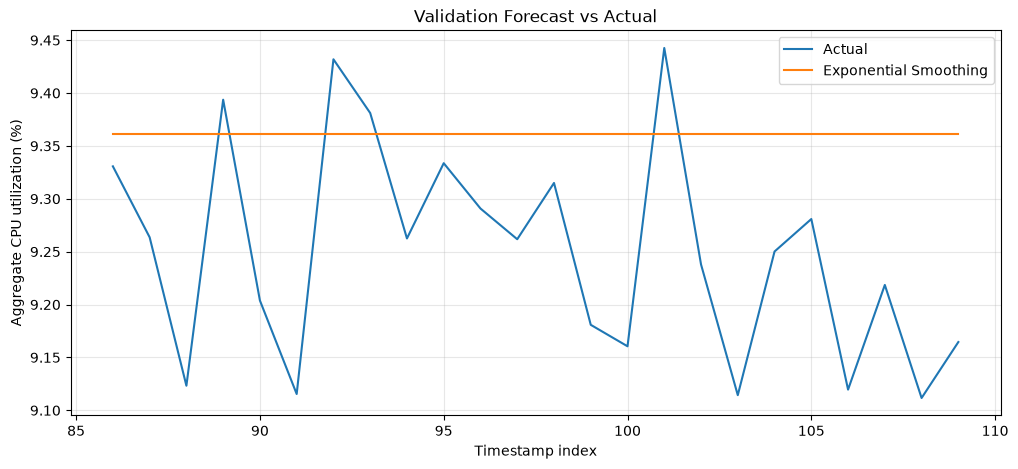

In [46]:
origin = 86

history = train["aggregate_cpu_utilization"].iloc[:origin].tolist()
actual = train["aggregate_cpu_utilization"].iloc[origin:origin + 24]

# Exponential smoothing forecast
ets_model = ExponentialSmoothing(
    history,
    trend=None,
    seasonal=None,
    initialization_method="estimated"
).fit()

ets_predictions = ets_model.forecast(24)

plt.figure(figsize=(12, 5))

plt.plot(
    actual.index,
    actual.values,
    label="Actual"
)

plt.plot(
    actual.index,
    ets_predictions,
    label="Exponential Smoothing"
)

plt.title("Validation Forecast vs Actual")
plt.xlabel("Timestamp index")
plt.ylabel("Aggregate CPU utilization (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [47]:
development_cpu = train["aggregate_cpu_utilization"].tolist()

final_ets_model = ExponentialSmoothing(
    development_cpu,
    trend=None,
    seasonal=None,
    initialization_method="estimated"
).fit()

holdout_cpu_predictions = final_ets_model.forecast(24)

holdout_predictions = pd.DataFrame({
    "timestamp": holdout["timestamp"].values,
    "active_vm_count": 10000,
    "aggregate_cpu_utilization": holdout_cpu_predictions
})

display(holdout_predictions)

,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.166976
1,33300,10000,9.166976
2,33600,10000,9.166976
3,33900,10000,9.166976
4,34200,10000,9.166976
5,34500,10000,9.166976
6,34800,10000,9.166976
7,35100,10000,9.166976
8,35400,10000,9.166976
9,35700,10000,9.166976


In [48]:
print("Prediction rows:", len(holdout_predictions))
print(
    "CPU range:",
    holdout_predictions["aggregate_cpu_utilization"].min(),
    "to",
    holdout_predictions["aggregate_cpu_utilization"].max()
)

print("\nMissing values:")
print(holdout_predictions.isna().sum())

Prediction rows: 24
CPU range: 9.166976017372917 to 9.166976017372917

Missing values:
timestamp                    0
active_vm_count              0
aggregate_cpu_utilization    0
dtype: int64


In [49]:
output_path = Path("../predictions.csv")

holdout_predictions.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())
print("\nColumns:")
print(holdout_predictions.columns.tolist())

print("\nShape:", holdout_predictions.shape)

Saved to: C:\forecasting_challenge\forecasting-challenge\predictions.csv

Columns:
['timestamp', 'active_vm_count', 'aggregate_cpu_utilization']

Shape: (24, 3)


In [50]:
saved_predictions = pd.read_csv(output_path)

print("Shape:", saved_predictions.shape)
print("Columns:", saved_predictions.columns.tolist())

display(saved_predictions.head())
display(saved_predictions.tail())

Shape: (24, 3)
Columns: ['timestamp', 'active_vm_count', 'aggregate_cpu_utilization']


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.166976
1,33300,10000,9.166976
2,33600,10000,9.166976
3,33900,10000,9.166976
4,34200,10000,9.166976


,timestamp,active_vm_count,aggregate_cpu_utilization
19,38700,10000,9.166976
20,39000,10000,9.166976
21,39300,10000,9.166976
22,39600,10000,9.166976
23,39900,10000,9.166976
